# Linear Model with Huber Loss 

  0%|          | 0/8 [00:00<?, ?it/s]

δ =  1.8


  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1410 [00:00<?, ?it/s]

Optimization Results: x =  [0.84125058 1.30807816 1.62942068] , ier =  1 , mesg =  The solution converged. , infodict =  {'nfev': 11, 'njev': 1, 'fjac': array([[-0.91067407,  0.41275278,  0.01754679],
       [-0.4101471 , -0.90838357,  0.08135508],
       [-0.04951875, -0.0668912 , -0.99653071]]), 'r': array([ 0.63750956, -0.56840512, -0.08436047,  0.71081253, -0.20420532,
        0.21365809]), 'qtf': array([ 6.09396086e-12,  4.12209018e-10, -4.12740319e-10]), 'fvec': array([ 1.19004806e-12,  2.37876385e-12, -2.92477154e-12])}
μ̃_arr:  [0.74064608 0.25935392]
σ̃ =  1.0106697391751533
Regressing on signal  0
ERM opt result:    message: CONVERGENCE: NORM_OF_PROJECTED_GRADIENT_<=_PGTOL
  success: True
   status: 0
      fun: 0.15954362246392528
        x: [-3.443e-01  4.680e-01 ... -3.785e+00  2.346e-03]
      nit: 27
      jac: [-1.837e-06 -1.996e-06 ... -5.206e-06 -1.331e-07]
     nfev: 32
     njev: 32
 hess_inv: <800x800 LbfgsInvHessProduct with dtype=float64>
Optimization Results: x 

 12%|█▎        | 1/8 [00:05<00:41,  6.00s/it]

... (32 outputs left out)

  0%|          | 0/3918 [00:00<?, ?it/s]

Optimization Results: x =  [0.40274235 1.18920848 0.26911942] , ier =  1 , mesg =  The solution converged. , infodict =  {'nfev': 13, 'njev': 1, 'fjac': array([[-0.96371941,  0.26501457,  0.03181457],
       [-0.26543302, -0.96408086, -0.00966451],
       [-0.02811058,  0.01775851, -0.99944706]]), 'r': array([ 0.63248302, -0.1636284 ,  0.75077484,  1.10017095, -0.8614565 ,
        2.93779709]), 'qtf': array([-6.49519913e-11, -5.42340839e-11, -2.35058237e-11]), 'fvec': array([-9.50850509e-13, -3.50164342e-13, -3.55271368e-13])}
μ̃_arr:  [0.81112395 0.18887605]
σ̃ =  0.672391152977024
Regressing on signal  0
ERM opt result:    message: CONVERGENCE: NORM_OF_PROJECTED_GRADIENT_<=_PGTOL
  success: True
   status: 0
      fun: 0.26034687454993344
        x: [ 4.968e-01  2.778e-02 ...  1.256e+00 -1.983e+00]
      nit: 10
      jac: [ 6.692e-07  5.774e-08 ...  2.334e-07 -6.865e-07]
     nfev: 12
     njev: 12
 hess_inv: <800x800 LbfgsInvHessProduct with dtype=float64>
Optimization Results: x =

100%|██████████| 8/8 [00:47<00:00,  5.98s/it]

σ̃ =  0.6384173721565821
Regressing on signal  1
ERM opt result:    message: CONVERGENCE: NORM_OF_PROJECTED_GRADIENT_<=_PGTOL
  success: True
   status: 0
      fun: 0.3846913105357144
        x: [-6.905e-01 -6.508e-01 ...  6.309e-01 -1.916e+00]
      nit: 10
      jac: [ 9.015e-07  4.312e-07 ...  8.815e-07 -3.934e-07]
     nfev: 12
     njev: 12
 hess_inv: <800x800 LbfgsInvHessProduct with dtype=float64>


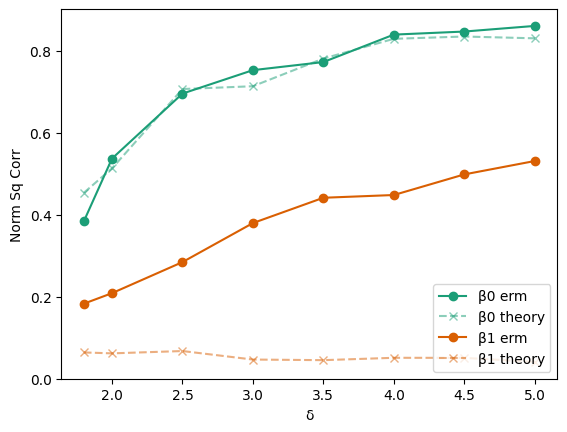

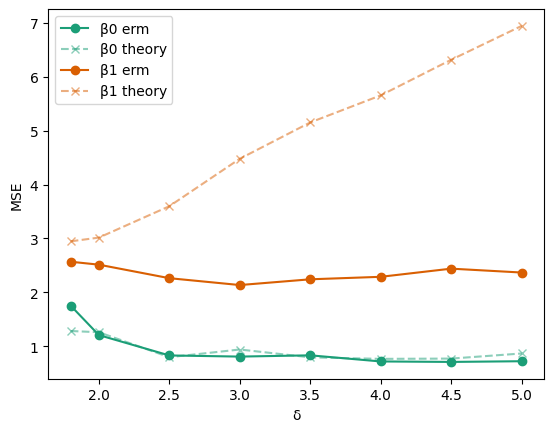

In [3]:
from WERM.config import unif_prior_to_η_ϕ
from WERM.config import η_to_ψ
from WERM.signal_priors import GaussianSignal
import WERM.model as model
import WERM.general_fixed_point_eqns as fp
import WERM.M_est_fixed_point_eqns as M_est
import WERM
import numpy as np
import jax.numpy as jnp # Not used in any randomness, all randomness is in numpy
import jax
import numpy.random as nprandom
import matplotlib.pyplot as plt
import scipy
from sklearn import linear_model
from functools import partial
from tqdm import tqdm
tqdm = partial(tqdm, position=0, leave=True)

p = 800
L = 2 # num signals. L-1 changepoints

δ_list = [1.8, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0]
noise_std = 0.25
# M = lambda u, v: jnp.power(u - v, 2)
M = lambda t: jnp.power(t, 2)

# def M(u, v, epsilon = 1.35):
#     residual = u - v
#     condition = jnp.abs(residual) < epsilon
#     squared_loss = jnp.square(residual)
#     linear_loss = 2 * epsilon * (jnp.abs(residual) - 0.5 * epsilon)
#     return jnp.where(condition, squared_loss, linear_loss)

# chgpt_locations = np.array([0.3, 0.7])
fractional_chgpt_locations = np.array([0.6])
# fractional_chgpt_locations = np.array([])
# chgpt_locations = np.array([])

erm_corr_list = [[] for ℓ_ in range(L)]
amp_corr_list = [[] for ℓ_ in range(L)]
erm_MSE_list = [[] for ℓ_ in range(L)]
amp_MSE_list = [[] for ℓ_ in range(L)]
theory_MSE_list = [[] for ℓ_ in range(L)]
comparison_corr_list = [[] for ℓ_ in range(L)]
comparison_MSE_list = [[] for ℓ_ in range(L)]

for i in tqdm(range(len(δ_list))):
    δ = δ_list[i]
    print("δ = ", δ)

    n = int(δ * p)
    if fractional_chgpt_locations.size != 0:
        true_chgpt_locations = lambda n: (n*fractional_chgpt_locations).astype(int)
        C_true = η_to_ψ(true_chgpt_locations(n), n)
    else:
        true_chgpt_locations = lambda n: np.array([])
        C_true = np.zeros(n).astype(int) # No changepoint, assume signal 1, not 0. 

    # --- Preliminaries ---
    # Changepoint locations
    Δ = lambda n: int(n/100)
    Lmin = 2
    Lmax = 2
    # p_l = 1/L * np.ones(L) # puts equal weight on all number of signals, set None otherwise. Best for estimating size. 
    p_l = None
    num_valid_configs, η_arr, p_η_arr, ϕ = unif_prior_to_η_ϕ(Lmin, Lmax, Δ(n), n, p_l = p_l) # Lxn matrix
    assert η_arr.shape == (num_valid_configs, Lmax-1) and \
        len(p_η_arr) == num_valid_configs
    assert ϕ.shape == (Lmax, n)

    if fractional_chgpt_locations.size == 0:
        # No chgpt prior
        for ℓ_ in range(L):
            ϕ[ℓ_, :] = np.ones(n)

    # Gaussian Signal Prior
    κ = 1.0
    # B̃_cov = κ**2 * δ * np.eye(L) # keeps the signal power fixed
    B̃_cov = κ**2 * δ * np.array([[1.0, 0.0], [0.0, 1.0]]) # keeps the signal power fixed
    signal_prior = GaussianSignal(B̃_cov)

    B̃ = signal_prior.sample(p)
    ρ = 1/δ * 1/p * B̃.T @ B̃

    # Generate the observation vector Y
    X = np.random.normal(0, np.sqrt(1/n), (n, p))

    # key = jax.random.PRNGKey(0)
    # ε = jax.random.t(key, 5, shape=(n, 1))
    # ε = np.random.standard_t(5, size=(n, ))
    ε = np.random.randn(n) * noise_std
    Θ = X @ B̃
    # y = lin_reg(Θ, C_true, noise_std).astype(np.float64).flatten()
    y = jax.vmap(model.q_linear_model, in_axes=(0, 0, 0))(Θ, C_true, ε)

    # --- Run Weighted ERM and compare with the fixed point equations --- #
    B̂ = np.zeros((p, L))

    # b, ν̃, κ̃ = fp.general_fp(M, ρ, δ, fractional_chgpt_locations, ϕ, ε, n, model.q_linear_model) # Compute the fixed point solution to general problem
    # κ̃_sqrt = jnp.linalg.cholesky(κ̃ + 1e-10 * jnp.eye(L))  # stabilize
    # G_sample = np.random.multivariate_normal(np.zeros((L, )), np.eye(L), size=(p,)) @ κ̃_sqrt.T

    for ℓ_ in range(L): 

        π = ϕ[ℓ_, :]
        # ε = np.random.normal(0, noise_std, n) # Sample noise equivalent to that of the model
        μ̃_arr, σ̃, μ_arr, σ = M_est.fp_linear_model_unif_prior(M, ρ, L, fractional_chgpt_locations, δ, n, noise_std)
        print("σ̃ = ", σ̃)
        β̂_theory = B̃ @ μ̃_arr + σ̃ * np.random.normal(0, 1, p)

        # β̂_theory = B̃ @ ν̃[:, ℓ_] + δ**(1/2) * G_sample[:, ℓ_]

        print("Regressing on signal ", ℓ_)
        sample_weight = ϕ[ℓ_, :] / np.sum(ϕ[ℓ_, :]) # make it so that it sums to 1 (for stability of optimization)

        # Find minimum of Huber loss
        # huber_loss_wrapper = lambda β: jnp.multiply(M(X @ β, y), sample_weight).sum() / sample_weight.sum()
        huber_loss_wrapper = lambda β: jnp.multiply(M(X @ β - y), sample_weight).sum() / sample_weight.sum()
        res = scipy.optimize.minimize(huber_loss_wrapper, np.zeros(p), jac = jax.grad(huber_loss_wrapper), method='L-BFGS-B')
        print("ERM opt result: ", res) 
        β̂ = res.x

        B̂[:, ℓ_] = β̂
        erm_corr_list[ℓ_].append(WERM.norm_sq_corr(β̂, B̃[:, ℓ_]))
        amp_corr_list[ℓ_].append(WERM.norm_sq_corr(β̂_theory, B̃[:, ℓ_]))

        comparison_corr_list[ℓ_].append(WERM.norm_sq_corr(β̂_theory.flatten(), β̂.flatten()))
        comparison_MSE_list[ℓ_].append(WERM.MSE(β̂_theory.flatten(), β̂.flatten()))
        erm_MSE_list[ℓ_].append(WERM.MSE(β̂.flatten(), B̃[:, ℓ_]))
        amp_MSE_list[ℓ_].append(WERM.MSE(β̂_theory.flatten(), B̃[:, ℓ_]))
        # G = np.random.randn(p)
        # theory_MSE_list[ℓ_].append(WERM.MSE(σ̃ * G, np.zeros(p)))

PAL = ['#1b9e77','#d95f02','#7570b3','#e7298a']
# Sqcorr plots
for ℓ_ in range(L):
    plt.errorbar(δ_list, erm_corr_list[ℓ_], label="β" + str(ℓ_) + " erm", marker="o", ls="-", c=PAL[ℓ_], alpha = 1.0)
    plt.errorbar(δ_list, amp_corr_list[ℓ_], label="β" + str(ℓ_) + " theory", marker="x", ls="--", c=PAL[ℓ_], alpha = 0.5)
# plt.ylim((0, 1))
plt.xlabel("δ")
plt.ylabel("Norm Sq Corr")
plt.legend()
plt.show()

# MSE plots
# plt.errorbar(δ_list, comparison_MSE_list[ℓ_], label="β" + str(ℓ_) + " comp", marker="D", ls="--", c=PAL[ℓ_], alpha = 1.0)
for ℓ_ in range(L):
    plt.errorbar(δ_list, erm_MSE_list[ℓ_], label="β" + str(ℓ_) + " erm", marker="o", ls="-", c=PAL[ℓ_], alpha = 1.0)
    plt.errorbar(δ_list, amp_MSE_list[ℓ_], label="β" + str(ℓ_) + " theory", marker="x", ls="--", c=PAL[ℓ_], alpha = 0.5)
# plt.errorbar(δ_list, theory_MSE_list[ℓ_], label="β" + str(ℓ_) + " theory", marker="x", ls="--", c=PAL[ℓ_], alpha = 1.0)
# plt.ylim((0, 2))
plt.xlabel("δ")
plt.ylabel("MSE")
plt.legend()
plt.show()

# Linear Model with change points: estimate ρ

In [ ]:
from WERM.config import unif_prior_to_η_ϕ
from WERM.config import η_to_ψ
from WERM.signal_priors import GaussianSignal
from WERM.model import *
from WERM.M_est_fixed_point_eqns import *
import WERM
import numpy as np
import jax.numpy as jnp # Not used in any randomness, all randomness is in numpy
import jax
import numpy.random as nprandom
import matplotlib.pyplot as plt
import scipy
from sklearn import linear_model
from functools import partial
from tqdm import tqdm
tqdm = partial(tqdm, position=0, leave=True)

p = 2000
L = 2 # num signals. L-1 changepoints

δ_list = [2.0]
noise_std = 0.2
M = lambda t: jnp.power(t, 2)

# chgpt_locations = np.array([0.3, 0.7])
fractional_chgpt_locations = np.array([0.5])
# fractional_chgpt_locations = np.array([])
# chgpt_locations = np.array([])

erm_corr_list = [[] for ℓ_ in range(L)]
amp_corr_list = [[] for ℓ_ in range(L)]
erm_MSE_list = [[] for ℓ_ in range(L)]
amp_MSE_list = [[] for ℓ_ in range(L)]
theory_MSE_list = [[] for ℓ_ in range(L)]
comparison_corr_list = [[] for ℓ_ in range(L)]
comparison_MSE_list = [[] for ℓ_ in range(L)]

for i in tqdm(range(len(δ_list))):
    δ = δ_list[i]
    print("δ = ", δ)

    n = int(δ * p)
    if fractional_chgpt_locations.size != 0:
        true_chgpt_locations = lambda n: (n*fractional_chgpt_locations).astype(int)
        C_true = η_to_ψ(true_chgpt_locations(n), n)
    else:
        true_chgpt_locations = lambda n: np.array([])
        C_true = np.zeros(n).astype(int) # No changepoint, assume signal 1, not 0. 

    # --- Preliminaries ---
    # Changepoint locations
    Δ = lambda n: int(n/100)
    Lmin = 2
    Lmax = 2
    # p_l = 1/L * np.ones(L) # puts equal weight on all number of signals, set None otherwise. Best for estimating size. 
    p_l = None
    num_valid_configs, η_arr, p_η_arr, ϕ = unif_prior_to_η_ϕ(Lmin, Lmax, Δ(n), n, p_l = p_l) # Lxn matrix
    assert η_arr.shape == (num_valid_configs, Lmax-1) and \
        len(p_η_arr) == num_valid_configs
    assert ϕ.shape == (Lmax, n)

    if fractional_chgpt_locations.size == 0:
        # No chgpt prior
        for ℓ_ in range(L):
            ϕ[ℓ_, :] = np.ones(n)

    # Gaussian Signal Prior
    κ = 2.3
    B̃_cov = κ**2 * δ * np.eye(L) # keeps the signal power fixed
    signal_prior = GaussianSignal(B̃_cov)

    B̃ = signal_prior.sample(p)
    ρ = 1/δ * 1/p * B̃.T @ B̃
    ρ̂ = ρ
    print("True ρ: ", ρ)

    # Generate the observation vector Y
    X = np.random.normal(0, np.sqrt(1/n), (n, p))
    Θ = X @ B̃
    y = lin_reg(Θ, C_true, noise_std).astype(np.float64).flatten()

    Δρ_arr = []
    # Ideas to fix: use the exact same noise vector, 
    for j in tqdm(range(10)): 
        # --- Run Weighted ERM and compare with the fixed point equations --- #
        B̂ = np.zeros((p, L))
        Θ̂_erm = np.zeros((n, L))
        Θ_t_erm = np.zeros((n, L))
        ν = np.zeros((L, L))
        κ_mat = np.zeros((L, L))

        for ℓ_ in range(L):

            # μ̃_arr, σ̃, μ_arr, σ = fp_linear_model_unif_prior(M, ρ, L, fractional_chgpt_locations, δ, n, noise_std)
            # μ̃_arr, σ̃, μ_arr, σ = fp_linear_model_unif_prior(M, ρ, L, fractional_chgpt_locations, δ, n, noise_std)
            # π = ϕ[ℓ_, :]
            π = np.ones(n) # Set to a trivial prior to test
            ε = np.random.normal(0, noise_std, n) # Sample noise equivalent to that of the model
            μ̃_arr, σ̃, μ_arr, σ, b = fp_lin_model(π, M, ρ̂, L, fractional_chgpt_locations, δ, n, ε)
            ν[:, ℓ_] = μ̃_arr
            κ_mat[ℓ_, ℓ_] = (σ̃)**2 / δ
            # print("σ̃ = ", σ̃)
            β̂_amp = B̃ @ μ̃_arr + σ̃ * np.random.normal(0, 1, p)

            # print("Regressing on signal ", ℓ_)
            sample_weight = π
            sk_lin_reg = linear_model.LinearRegression(n_jobs = 2, fit_intercept = False)
            sk_lin_reg.fit(X, y, sample_weight = sample_weight)
            β̂ = sk_lin_reg.coef_

            B̂[:, ℓ_] = β̂
            Θ̂_erm[:, ℓ_] = X @ β̂
            print("### --- Debiasing... --- ###")
            Θ_t_erm[:, ℓ_] = debias_M_est(X @ β̂, y, b, π, X @ β̂)
            # loss = lambda u, v: M(u - v)
            # β̂_amp_algo, θ̂_amp_algo, β_t, θ_t = WERM.amp(X, y, n, p, π, loss, max_iter = 20)
            # Θ_t_erm[:, ℓ_] = θ_t
            
            # erm_corr_list[ℓ_].append(WERM.norm_sq_corr(β̂, B̃[:, ℓ_]))
            # amp_corr_list[ℓ_].append(WERM.norm_sq_corr(β̂_amp, B̃[:, ℓ_]))

            # comparison_corr_list[ℓ_].append(WERM.norm_sq_corr(β̂_amp.flatten(), β̂.flatten()))
            # comparison_MSE_list[ℓ_].append(WERM.MSE(β̂_amp.flatten(), β̂.flatten()))
            # erm_MSE_list[ℓ_].append(WERM.MSE(β̂.flatten(), B̃[:, ℓ_]))
            # amp_MSE_list[ℓ_].append(WERM.MSE(β̂_amp.flatten(), B̃[:, ℓ_]))
            # G = np.random.randn(p)
            # theory_MSE_list[ℓ_].append(WERM.MSE(σ̃ * G, np.zeros(p)))

        # Solve for ρ
        # Check whether \nu^T \rho \nu + \kappa is positive definite and whether ν is invertible
        rhs = ν.T @ ρ @ ν + κ_mat
        assert np.all(np.linalg.eigvals(rhs) > 0)

        # ρ̂ = np.linalg.inv(ν).T @ ((1/n * Θ_t_erm.T @ Θ_t_erm) - κ_mat) @ np.linalg.inv(ν) # Attempt to solve for ρ using a solver instead?
        ρ̂ = ρ
        lhs = (1/n * Θ_t_erm.T @ Θ_t_erm)
        print("lhs: ", lhs)
        print("rhs: ", rhs)
        print("lhs - rhs: ", lhs - rhs)
        print("ν: ", ν)
        print("κ_mat: ", κ_mat)

        print("ρ: ", ρ)
        print("ρ̂: ", ρ̂)
        print("Δρ: ", np.linalg.norm(ρ - ρ̂))
        print("ρ - ρ̂: ", ρ - ρ̂)
        Δρ_arr.append(np.linalg.norm(ρ - ρ̂))

    plt.plot(Δρ_arr)
    plt.title("Δρ")
    plt.show()

PAL = ['#1b9e77','#d95f02','#7570b3','#e7298a']
for ℓ_ in range(L):
    # Sqcorr plots
    plt.errorbar(δ_list, erm_corr_list[ℓ_], label="β" + str(ℓ_) + " erm", marker="o", ls="-", c=PAL[ℓ_], alpha = 1.0)
    plt.errorbar(δ_list, amp_corr_list[ℓ_], label="β" + str(ℓ_) + " amp", marker="x", ls="--", c=PAL[ℓ_], alpha = 0.5)
    plt.ylim((0, 1))
    plt.xlabel("δ")
    plt.ylabel("Norm Sq Corr")
    plt.legend()
    plt.show()

    # MSE plots
    # plt.errorbar(δ_list, comparison_MSE_list[ℓ_], label="β" + str(ℓ_) + " comp", marker="D", ls="--", c=PAL[ℓ_], alpha = 1.0)
    plt.errorbar(δ_list, erm_MSE_list[ℓ_], label="β" + str(ℓ_) + " erm", marker="o", ls="-", c=PAL[ℓ_], alpha = 1.0)
    plt.errorbar(δ_list, amp_MSE_list[ℓ_], label="β" + str(ℓ_) + " amp", marker="x", ls="--", c=PAL[ℓ_], alpha = 0.5)
    # plt.errorbar(δ_list, theory_MSE_list[ℓ_], label="β" + str(ℓ_) + " theory", marker="x", ls="--", c=PAL[ℓ_], alpha = 1.0)
    plt.ylim((0, 2))
    plt.xlabel("δ")
    plt.ylabel("MSE")
    plt.legend()
    plt.show()

  0%|          | 0/1 [00:00<?, ?it/s]

δ =  2.0


  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/4898 [00:00<?, ?it/s]

True ρ:  [[5.30503167 0.06057046]
 [0.06057046 5.04832244]]


  0%|          | 0/10 [00:00<?, ?it/s]

# Linear Model without change points: estimate γ

In [ ]:
from WERM.config import unif_prior_to_η_ϕ
from WERM.config import η_to_ψ
from WERM.signal_priors import GaussianSignal
from WERM.model import *
from WERM.M_est_fixed_point_eqns import *
import WERM
import numpy as np
import jax.numpy as jnp # Not used in any randomness, all randomness is in numpy
import jax
import numpy.random as nprandom
import matplotlib.pyplot as plt
import scipy
from sklearn import linear_model
from functools import partial
from tqdm import tqdm
tqdm = partial(tqdm, position=0, leave=True)

p = 2000
L = 1 # num signals. L-1 changepoints

δ_list = [3.0 for _ in range(30)]
noise_std = 0.2
# M = lambda t: jnp.power(t, 2)

def huber_loss(t, epsilon = 1.35):
    residual = t
    condition = jnp.abs(residual) < epsilon
    squared_loss = jnp.square(residual)
    linear_loss = 2 * epsilon * (jnp.abs(residual) - 0.5 * epsilon)
    return jnp.where(condition, squared_loss, linear_loss)
def M(t): return huber_loss(t)

erm_corr_list = [[] for ℓ_ in range(L)]
amp_corr_list = [[] for ℓ_ in range(L)]
erm_MSE_list = [[] for ℓ_ in range(L)]
amp_MSE_list = [[] for ℓ_ in range(L)]
theory_MSE_list = [[] for ℓ_ in range(L)]
comparison_corr_list = [[] for ℓ_ in range(L)]
comparison_MSE_list = [[] for ℓ_ in range(L)]

Δρ_trials_list = [[] for _ in δ_list]

for i in tqdm(range(len(δ_list))):
    δ = δ_list[i]
    print("δ = ", δ)

    n = int(δ * p)

    # Gaussian Signal Prior
    γ_squared = 2.3
    B̃_cov = γ_squared * δ * np.eye(L) # keeps the signal power fixed
    signal_prior = GaussianSignal(B̃_cov)

    B̃ = signal_prior.sample(p)
    ρ = 1/δ * 1/p * B̃.T @ B̃
    ρ̂ = np.eye(L)
    print("True ρ: ", ρ)

    # Generate the observation vector Y
    X = np.random.normal(0, np.sqrt(1/n), (n, p))
    Θ = X @ B̃
    ε = np.random.normal(0, noise_std, n) # Sample noise equivalent to that of the model
    y = Θ.flatten() + ε.flatten()

    Δρ_arr = [np.linalg.norm(ρ - ρ̂)]
    print("Δρ: ", np.linalg.norm(ρ - ρ̂))
    # Ideas to fix: use the exact same noise vector, 
    for j in tqdm(range(4)): 
        # --- Run Weighted ERM and compare with the fixed point equations --- #
        B̂ = np.zeros((p, L))
        Θ̂_erm = np.zeros((n, L))
        Θ_t_erm = np.zeros((n, L))
        ν = np.zeros((L, L))
        κ_mat = np.zeros((L, L))

        # π = ϕ[ℓ_, :]
        π = np.ones(n) # Set to a trivial prior to test
        ε = np.random.normal(0, noise_std, n) # Sample noise equivalent to that of the model
        fractional_chgpt_locations = np.array([])
        μ̃_arr, σ̃, μ_arr, σ, b = fp_lin_model(π, M, ρ̂, L, fractional_chgpt_locations, δ, n, ε)
        ν = μ̃_arr
        κ_mat = (σ̃)**2 / δ
        # print("σ̃ = ", σ̃)
        β̂_amp = B̃ @ μ̃_arr + σ̃ * np.random.normal(0, 1, p)

        # print("Regressing on signal ", ℓ_)
        # sample_weight = π
        # sk_lin_reg = linear_model.LinearRegression(n_jobs = 2, fit_intercept = False)
        # sk_lin_reg.fit(X, y, sample_weight = sample_weight)
        # β̂ = sk_lin_reg.coef_

        # B̂[:, 0] = β̂
        # Θ̂_erm[:, 0] = X @ β̂
        print("### --- Debiasing... --- ###")
        # Run actual AMP
        loss = lambda u, v: M(u - v)
        β̂_amp_algo, θ̂_amp_algo, β_t, θ_t = WERM.amp(X, y, n, p, π, loss, max_iter = 20)
        Θ_t_erm[:, 0] = θ_t
        # Θ_t_erm[:, 0] = debias_M_est(X @ β̂, y, b, π, X @ β̂)

        # Solve for ρ
        # Check whether \nu^T \rho \nu + \kappa is positive definite and whether ν is invertible
        rhs = ν[0]**2 * ρ[0] + κ_mat
        # ρ̂ = np.linalg.inv(ν).T @ ((1/n * Θ_t_erm.T @ Θ_t_erm) - κ_mat) @ np.linalg.inv(ν) # Attempt to solve for ρ using a solver instead?
        ρ̂ = ((1/n * Θ_t_erm.T @ Θ_t_erm) - κ_mat) * (ν[0])**(-2) # Attempt to solve for ρ using a solver instead?
        # ρ̂ = ρ
        lhs = (1/n * Θ_t_erm.T @ Θ_t_erm)
        print("lhs: ", lhs)
        print("rhs: ", rhs)
        print("lhs - rhs: ", lhs - rhs)
        print("ν: ", ν)
        print("κ_mat: ", κ_mat)

        print("ρ: ", ρ)
        print("ρ̂: ", ρ̂)
        print("Δρ: ", np.linalg.norm(ρ - ρ̂))
        print("ρ - ρ̂: ", ρ - ρ̂)
        Δρ_arr.append(np.linalg.norm(ρ - ρ̂))

    plt.plot(Δρ_arr)
    plt.title("Δρ")
    plt.show()

    Δρ_trials_list[i] = (ρ - ρ̂)[0][0]

  0%|          | 0/30 [00:00<?, ?it/s]

δ =  3.0
True ρ:  [[2.29926312]]
Δρ:  1.2992631192620925


  0%|          | 0/4 [00:00<?, ?it/s]

Optimization Results: x =  [0.13915975 0.25      ] , ier =  1 , mesg =  The solution converged. , infodict =  {'nfev': 17, 'njev': 2, 'fjac': array([[-0.99974797, -0.02245001],
       [ 0.02245001, -0.99974797]]), 'r': array([ 0.67834903, -0.34038738,  2.71251879]), 'qtf': array([ 1.50002317e-10, -1.97273537e-10]), 'fvec': array([ 6.63358257e-14, -8.23785484e-14])}
μ̃_arr:  [1.]
### --- Debiasing... --- ###


  0%|          | 0/20 [00:00<?, ?it/s]

c:  -0.8965
Normalized MSE:  inf
c:  -1.1273399083057893
Normalized MSE:  0.0016907894014213808
c:  -1.2565751252482205
Normalized MSE:  6.540006530397817e-05
c:  -1.306726102282859
Normalized MSE:  2.9219610616825734e-05
c:  -1.3243446746573966
Normalized MSE:  1.106512042235334e-05
c:  -1.3303235869833683
Normalized MSE:  3.967475627603228e-06
c:  -1.3323285725124046
Normalized MSE:  1.427153942515998e-06
c:  -1.3329982447177355
Normalized MSE:  5.042366267769913e-07
c:  -1.333221618410936
Normalized MSE:  1.7466464331795598e-07
c:  -1.3332960929457154
Normalized MSE:  5.8297022484319916e-08
c:  -1.3333209196396467
Normalized MSE:  1.945813197342021e-08
c:  -1.3333291954097533
Normalized MSE:  6.260100145377167e-09
c:  -1.3333319540226187
Normalized MSE:  1.961548376423914e-09
c:  -1.333332873562779
Normalized MSE:  6.610417705828455e-10
c:  -1.3333331800764463
Normalized MSE:  2.0970115871136702e-10
c:  -1.3333332822477004
Normalized MSE:  6.669199798211594e-11
c:  -1.33333331630478

 25%|██▌       | 1/4 [01:18<03:55, 78.51s/it]

c:  -1.3333333327026462
Normalized MSE:  6.334287879950161e-13
lhs:  [[2.31524884]]
rhs:  [2.31862856]
lhs - rhs:  [[-0.00337972]]
ν:  [1.]
κ_mat:  0.01936543673002991
ρ:  [[2.29926312]]
ρ̂:  [[2.2958834]]
Δρ:  0.003379716920655529
ρ - ρ̂:  [[0.00337972]]
Optimization Results: x =  [0.1420479 0.25     ] , ier =  1 , mesg =  The solution converged. , infodict =  {'nfev': 18, 'njev': 1, 'fjac': array([[-0.99960252, -0.02819208],
       [ 0.02819208, -0.99960252]]), 'r': array([ 0.5936437 , -1.69293612,  3.01618855]), 'qtf': array([ 2.91613955e-09, -7.10659368e-10]), 'fvec': array([ 6.55919763e-13, -1.41220369e-13])}
μ̃_arr:  [1.]
### --- Debiasing... --- ###


  0%|          | 0/20 [00:00<?, ?it/s]

c:  -0.8993333333333333
Normalized MSE:  inf
c:  -1.1317281112530153
Normalized MSE:  0.001837767667786363
c:  -1.258178551717071
Normalized MSE:  6.489499300489029e-05
c:  -1.3073036103895601
Normalized MSE:  2.8373919240339e-05
c:  -1.3245423455302847
Normalized MSE:  1.054990065994643e-05
c:  -1.3303900669562407
Normalized MSE:  3.7810280989929356e-06
c:  -1.3323507986102618
Normalized MSE:  1.4109993676862359e-06
c:  -1.3330056607841476
Normalized MSE:  4.845417617096595e-07
c:  -1.333224091252456
Normalized MSE:  1.6100080078397194e-07


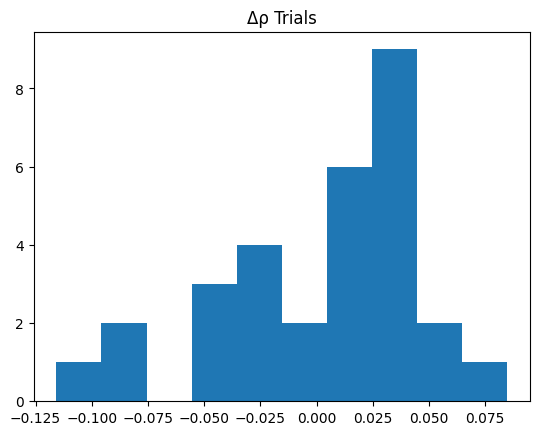

Mean:  0.0012376678106404526
Std:  0.04540794343623711


In [3]:
# Δρ_trials_list = np.array(Δρ_trials_list)
# Plot a histogram of Δρ_trials_list
plt.hist(Δρ_trials_list)
plt.title("Δρ Trials")
plt.show()

print("Mean: ", np.mean(Δρ_trials_list))
print("Std: ", np.std(Δρ_trials_list))